# Can ML forecast wireless complaint workloads better than a baseline?

**Himanshu Jadaun | Project 02 | November 2, 2026**

This notebook explains the executed `study.py` experiment. It reads its saved predictions and independently recomputes results; it does not claim to retrain the models inside notebook cells. Run `python run_study.py` for source ingestion and full fitting, or `python study.py --snapshot` for an exact input-snapshot rerun.

**New technique:** direct multi-horizon count forecasting with rolling-origin residual distributions. We forecast four separate weekly targets from the same origin. A separate model for each horizon avoids feeding invented future observations into later predictions.

**Hypothesis:** a nonlinear count model may outperform a recent-average workload forecast. The prespecified development MAE, not final evaluation performance, decides which candidate is selected.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display, Image
from study import load_data, score, features
R=Path('results')
weekly,daily,audit,manifest,_=load_data(snapshot=True)
pred=pd.read_csv(R/'backtest_predictions.csv')
selection=json.loads((R/'selection_locked_before_test.json').read_text())
audit

Out[0]: 
{'observed_complaints': 1259229,
 'daily_issue_groups': 25888,
 'weeks': 460,
 'first_week': '2018-01-01',
 'last_week': '2026-10-19',
 'zero_count_days': 8,
 'duplicate_ids_in_scope': 0,
 'missing_submission_date_all_time_scope': 0,
 'date_created_vs_ticket_created_day_mismatches': 118111,
 'unwanted_call_share': 0.6163684286178288,
 'snapshot_not_vintage': True,
 'missing_days_policy': 'Reindex full calendar; absent days are assumed zero, not proven ingestion uptime'}


## 1. Audit the unit of analysis before creating features

The observed unit is an FCC complaint ticket, filtered to phone service with a wireless method. The modelling target is a weekly total, not a subscriber rate. Source reports are self-selected and unverified. More complaints can reflect reporting behavior, spam, media attention, service changes, or data processing; the counts do not identify a cause.

`ticket_created` is explicitly documented as the submission timestamp. `date_created` is an undescribed calendar field, and its day can differ from the UTC submission day. The audit amendment records why the study uses UTC submission dates. We never use the consumer-reported incident date to fabricate a prediction timeline.

The source API groups tickets on the server; no phone numbers, addresses, ticket identifiers, or subscriber information are downloaded into the study. Duplicate checks compare aggregate row counts against distinct-ID counts.

Anonymous aggregate hash: 9196a906f031aed54192edca5955b61a346da1750b9fb773acc14531acc7fb6d


,all_wireless,excluding_unwanted_calls
count,460.0,460.0
mean,2737.5,1050.2
std,1208.3,796.3
min,10.0,7.0
25%,2052.8,578.5
50%,2365.5,828.0
75%,3319.0,1237.2
max,9579.0,7582.0


,complaints
issue,
Unwanted Calls,776149
Billing,210575
Equipment,82204
Availability (including rural call completion),77926
Number Portability (keeping your number if you change providers),40012
Privacy,25599
Cramming (unauthorized charges on your phone bill),23856
Interference (including signal jammers),19679
,2706


,all_wireless,excluding_unwanted_calls
week_start,,
2019-01-07,18,15
2019-01-14,11,10
2025-10-06,25,18
2025-10-13,20,13
2025-10-20,35,33
2025-10-27,22,16
2025-11-03,10,7


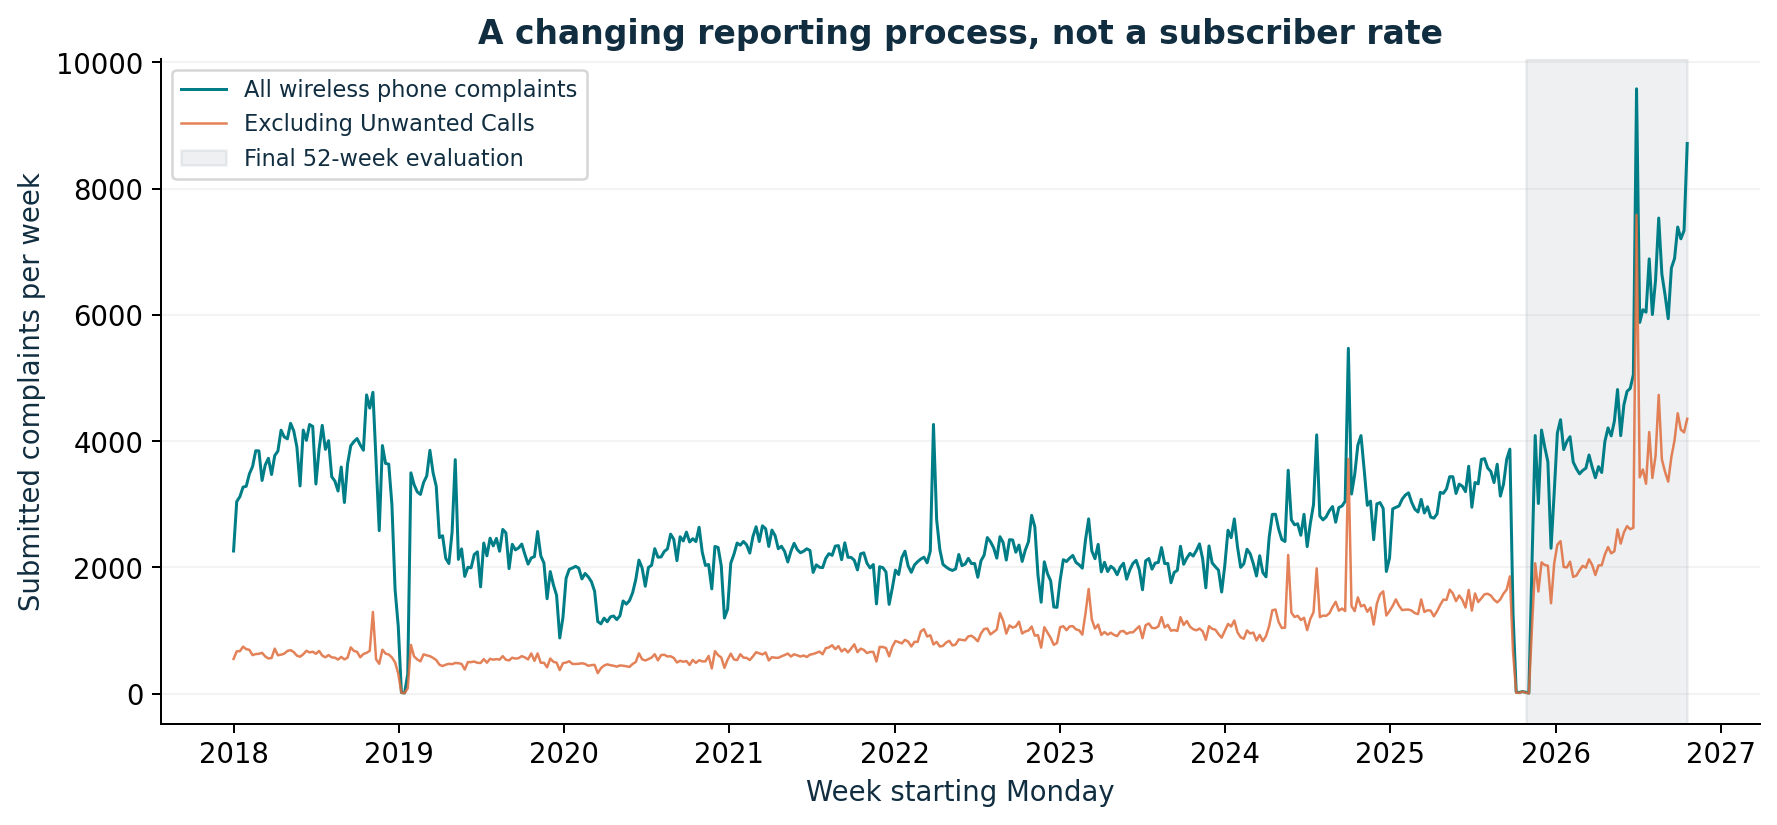

In [2]:
display(weekly.describe().round(1))
display(daily.groupby('issue').n.sum().sort_values(ascending=False).head(10).to_frame('complaints'))
display(weekly[weekly.all_wireless<100])
print('Anonymous aggregate hash:',manifest['snapshot_aggregate_sha256'])
display(Image('figures/01_history.png'))

## 2. Define a forecast origin and protect every boundary

An origin is Monday 00:00 UTC. Its newest allowed observed week ends immediately before that origin. Four predictions cover the following four weeks. Origins advance by four weeks, so final evaluation targets do not overlap.

Features: log-transformed lags 1, 2, 3, 4, 8, 13, 26, 52; log means over 4, 13, 26, 52 preceding weeks; log 13-week standard deviation; and two annual Fourier harmonics of the known target calendar. Scaling for ridge is fit on each origin's training data. Labels for horizon h enter training only if their target week precedes the current origin.

Development: 104 weeks, October 30, 2023-October 26, 2025. Final evaluation: 52 weeks, October 27, 2025-October 25, 2026. Final outcomes may enter later-origin training once observed; model choice and hyperparameters stay frozen. This is sequential evaluation of an updating forecast system.

In [3]:
display(pd.crosstab(pred[pred.model=='recent_mean_4'].split,pred[pred.model=='recent_mean_4'].horizon))
trace=pd.read_csv(R/'training_trace.csv')
assert (trace.latest_training_target<trace.origin).all()
assert (trace.latest_feature_observation<trace.origin).all()
print('All',len(trace),'recorded fits have strictly historical training targets.')
y=weekly.all_wireless.to_numpy(float)
altered=y.copy(); altered[300:]=1_000_000
for h in [1,2,3,4]:
    np.testing.assert_array_equal(features(y,weekly.index,h)[248],features(altered,weekly.index,h)[248])
print('Future-value perturbation leaves origin features unchanged.')

All 1824 recorded fits have strictly historical training targets.
Future-value perturbation leaves origin features unchanged.


horizon,1,2,3,4
split,,,,
development,26,26,26,26
test,13,13,13,13
warmup,37,37,37,37


## 3. Compare useful alternatives

1. Recent four-week mean: a responsive level baseline, constant within each forecast batch.
2. Seasonal naive: repeat the weekly count from 52 weeks earlier.
3. Ridge regression on log1p counts: regularized linear relationships, training-only scaling, alpha 10. Exponentiation has no mean-bias correction; evaluate it empirically rather than calling it an unbiased count mean.
4. Poisson histogram gradient boosting: nonnegative mean-count objective with seven or fifteen leaves; 100 iterations, learning rate 0.05, L2 penalty 10. These two configurations are the complete nonlinear search budget.

The Poisson loss does not assert that the data follow a Poisson distribution. In particular, this study does not obtain uncertainty by assuming variance equals mean. It estimates forecast intervals from preceding out-of-sample errors.

In [4]:
display(pd.DataFrame(selection['development_metrics']).round(3))
print('Overall selection:',selection['selected_model'])
print('ML challenger:',selection['selected_ml_candidate'])
print('Baseline:',selection['selected_baseline'])

Overall selection: recent_mean_4
ML challenger: boost_poisson_deep
Baseline: recent_mean_4


,model,n_forecasts,n_origins,mae,wape,bias,rmse,coverage80,mean_width80,interval_score80,n_interval_forecasts
0,recent_mean_4,104,26,444.947,0.160,69.721,791.589,0.654,798.536,2887.058,104
1,boost_poisson_deep,104,26,520.213,0.187,-95.397,832.425,0.577,825.804,3186.231,104
2,boost_poisson_small,104,26,531.595,0.191,-123.124,826.985,0.577,860.669,3163.793,104
3,ridge_log,104,26,663.170,0.239,-420.787,886.707,0.654,987.401,3058.189,104
4,seasonal_naive_52,104,26,792.625,0.285,-447.702,1089.929,0.510,1053.284,4062.082,104


## 4. Evaluate point accuracy and interval quality separately

Each model/horizon obtains a nominal 80% interval by adding the 10th and 90th percentiles of the last 26 available origin errors to its current point prediction, clipping at zero. At least 13 earlier origin errors are required. All calibration targets precede the new origin. Errors are signed, so intervals can be asymmetric around the point forecast. The point forecast need not sit at the interval midpoint.

These are empirical residual prediction intervals. Serial dependence and distribution change mean that there is no finite-sample 80% coverage guarantee. We measure actual coverage, interval width, and the 80% interval score: width + 10 times the amount a missed outcome lies outside the interval. Wider intervals alone cannot automatically win this score.

,model,n_forecasts,n_origins,mae,wape,bias,rmse,coverage80,mean_width80,interval_score80,n_interval_forecasts
2,recent_mean_4,52,13,783.644,0.166,-563.269,1242.284,0.692,1309.567,4883.149,52
0,boost_poisson_deep,52,13,1062.511,0.225,-849.829,1606.217,0.558,1505.884,5600.280,52
1,boost_poisson_small,52,13,1068.600,0.227,-848.803,1614.986,0.558,1534.357,5702.589,52
3,ridge_log,52,13,1605.658,0.341,-1478.189,2008.997,0.385,1282.765,6541.806,52
4,seasonal_naive_52,52,13,2094.346,0.444,-1767.962,2868.695,0.481,1294.596,11362.385,52


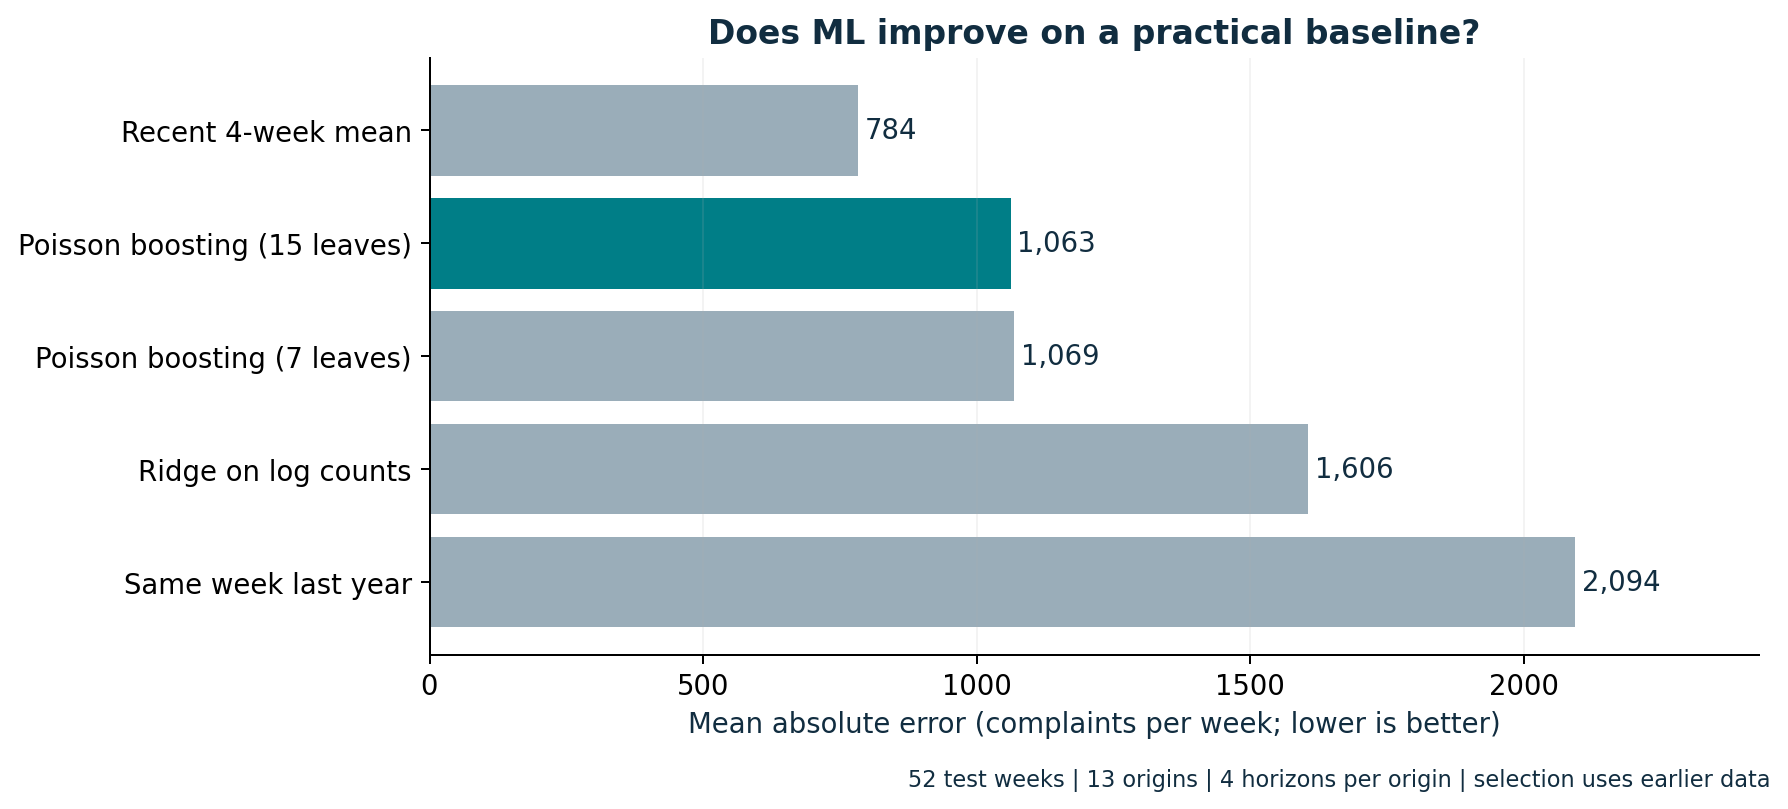

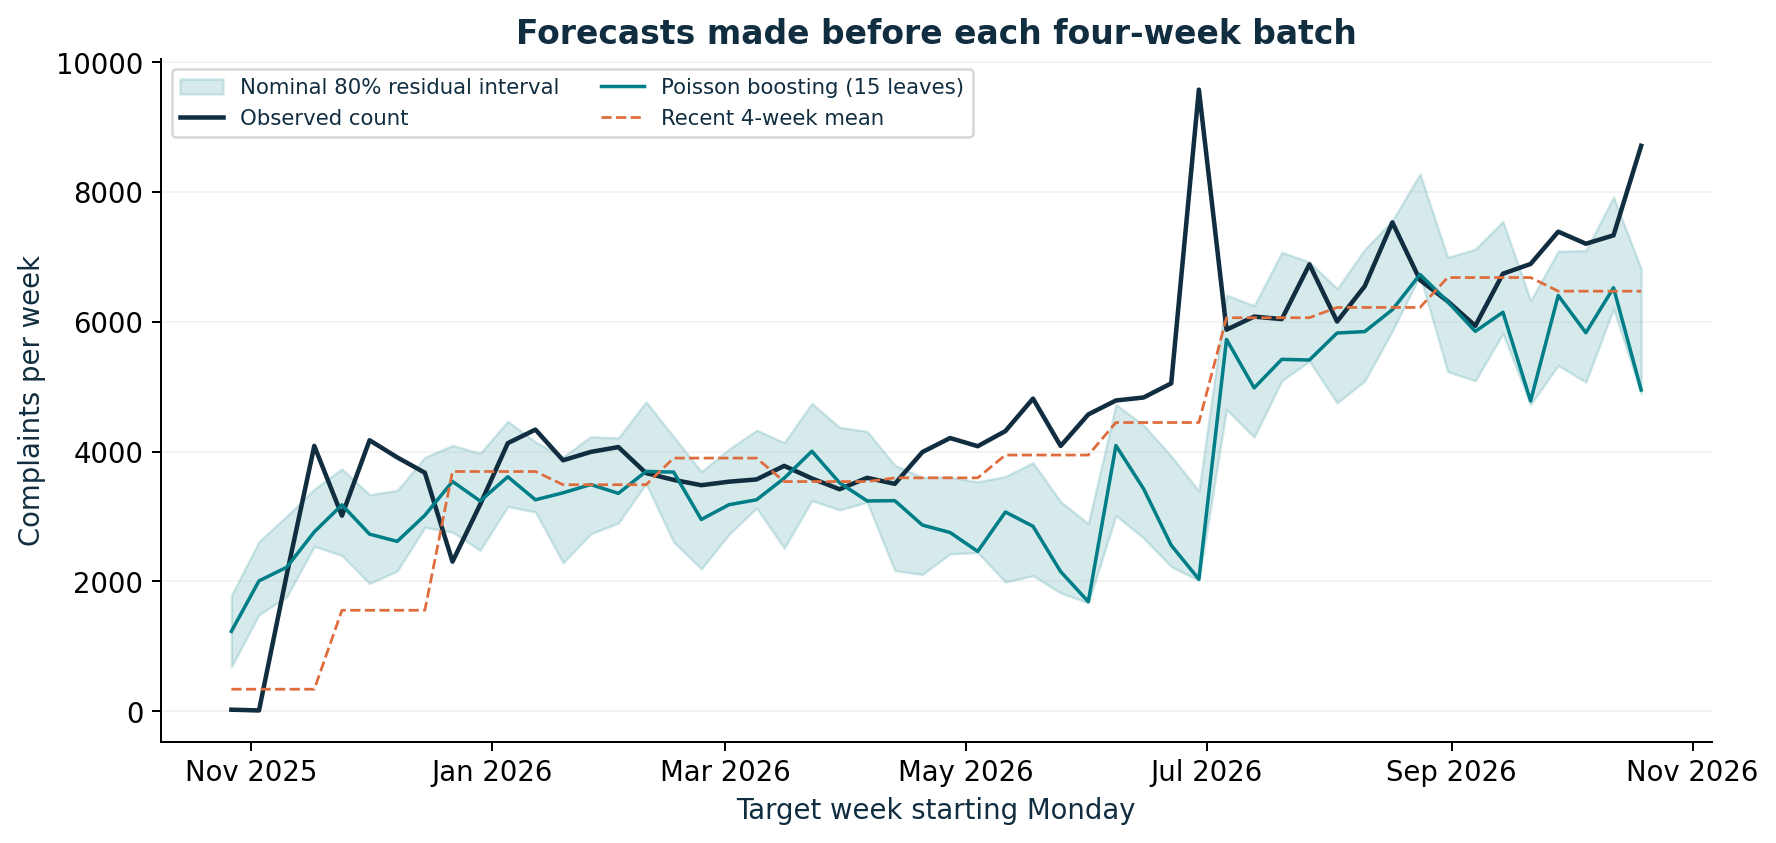

In [5]:
test=pred[pred.split=='test']
display(score(test).round(3))
display(Image('figures/02_model_comparison.png'))
display(Image('figures/03_test_forecasts.png'))

## 5. Quantify comparison uncertainty without pretending folds are independent

There are 52 test predictions, but only 13 forecast origins. We preserve all four horizons per origin, then resample circular blocks of three origins (12 weeks) for a paired MAE-difference interval. Positive differences mean the ML challenger has larger error than the baseline.

With 13 origins this interval is approximate. It is conditional on the observed snapshot and the frozen forecast sequence. It does not refit the pipeline, represent unknown source revisions, or establish universal superiority.

In [6]:
json.loads((R/'comparison_uncertainty.json').read_text())

Out[0]: 
{'comparison': 'boost_poisson_deep minus recent_mean_4',
 'mae_difference': 278.8672196620792,
 'conditional_95pct_block_bootstrap_ci': [-195.64573104798438,
  787.0249236465719],
 'origins': 13,
 'block_origins': 3,
 'resamples': 2000,
 'limitations': 'Small number of origins; conditional on this snapshot and fitted forecasts. No model refitting or data-revision uncertainty; not an IID-fold test.'}


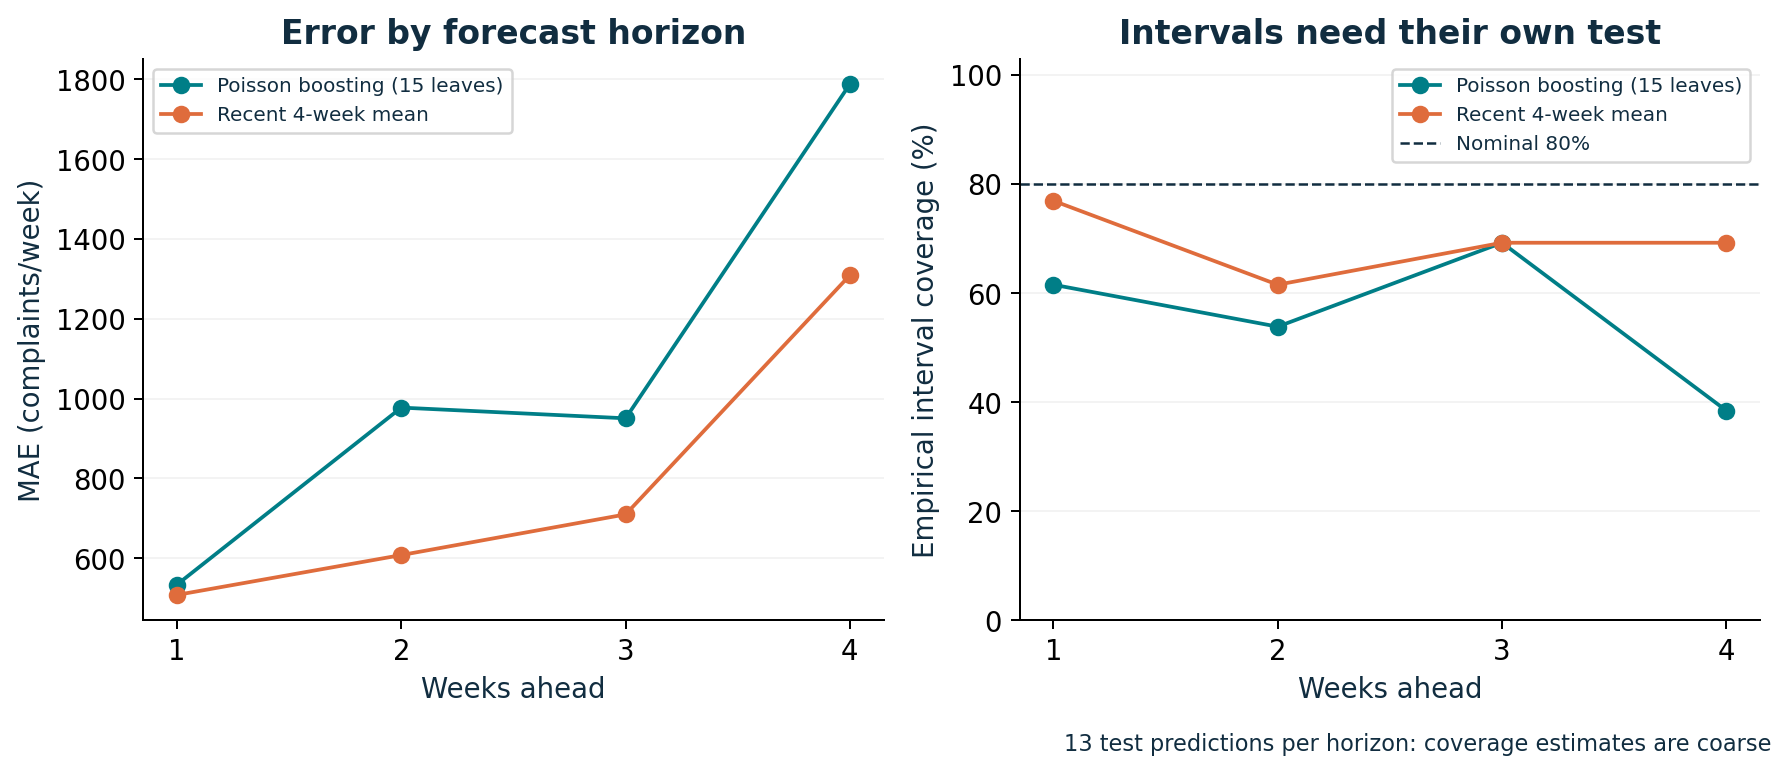

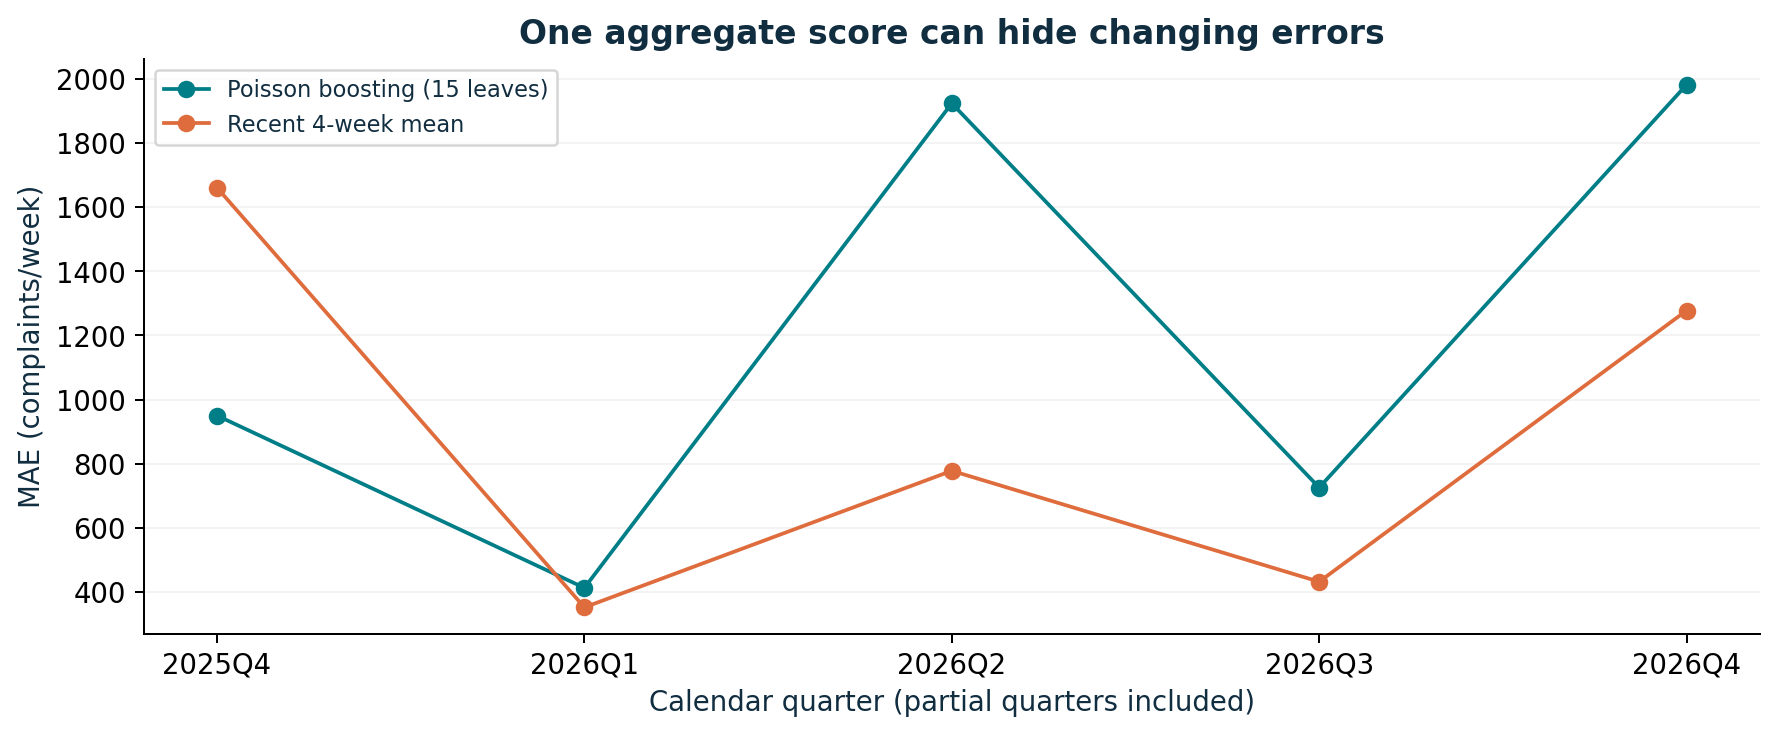

,model,n_forecasts,n_origins,mae,wape,bias,rmse,coverage80,mean_width80,interval_score80,n_interval_forecasts,error_slice,development_p90
0,recent_mean_4,41,13,821.043,0.155,-730.262,1326.921,0.732,1334.860,5145.012,41,above_dev_p90,3566.3
1,boost_poisson_deep,41,13,1197.790,0.226,-1171.894,1757.508,0.512,1544.411,6105.676,41,above_dev_p90,3566.3
2,boost_poisson_small,41,13,1202.045,0.227,-1174.807,1770.368,0.512,1576.834,6236.870,41,above_dev_p90,3566.3
3,ridge_log,41,13,1845.557,0.349,-1761.435,2223.483,0.293,1317.932,7526.661,41,above_dev_p90,3566.3
4,seasonal_naive_52,41,13,2327.024,0.440,-2327.024,3102.810,0.415,1315.049,12124.195,41,above_dev_p90,3566.3
5,boost_poisson_deep,11,6,558.290,0.218,350.596,826.517,0.727,1362.282,3716.528,11,at_or_below_dev_p90,3566.3
6,boost_poisson_small,11,6,571.214,0.223,366.305,804.707,0.727,1376.034,3711.177,11,at_or_below_dev_p90,3566.3
7,recent_mean_4,11,6,644.250,0.252,59.159,856.022,0.545,1215.295,3907.114,11,at_or_below_dev_p90,3566.3
8,ridge_log,11,6,711.490,0.278,-422.450,807.724,0.727,1151.690,2870.984,11,at_or_below_dev_p90,3566.3
9,seasonal_naive_52,11,6,1227.091,0.480,315.818,1737.416,0.727,1218.364,8522.909,11,at_or_below_dev_p90,3566.3


In [7]:
display(Image('figures/04_horizon_diagnostics.png'))
display(Image('figures/05_period_errors.png'))
display(pd.read_csv(R/'error_slices.csv').round(3))

## 6. Challenge the target definition

Unwanted Calls may dominate the primary target. The sensitivity repeats the frozen design after removing that issue category. It retains the primary model selection for the comparison and reports every candidate transparently. This is an exploratory sensitivity, not a second opportunity to choose a favorable final-test winner.

In [8]:
display(pd.read_csv(R/'sensitivity_metrics.csv').round(3))
display(pd.read_csv(R/'low_reporting_score_sensitivity.csv').round(3))
print('Primary model choices remain:',selection['selected_ml_candidate'],'versus',selection['selected_baseline'])

Primary model choices remain: boost_poisson_deep versus recent_mean_4


,model,n_forecasts,n_origins,mae,wape,bias,rmse,coverage80,mean_width80,interval_score80,n_interval_forecasts
0,recent_mean_4,52,13,469.692,0.176,-315.135,895.179,0.654,656.918,3383.000,52
1,boost_poisson_deep,52,13,614.235,0.230,-507.737,979.097,0.442,735.934,3093.818,52
2,boost_poisson_small,52,13,632.448,0.237,-528.713,996.481,0.365,729.354,3261.240,52
3,ridge_log,52,13,739.300,0.277,-524.403,1099.028,0.538,812.980,4078.487,52
4,seasonal_naive_52,52,13,1445.500,0.541,-1330.385,1897.389,0.154,902.038,7777.808,52


,model,n_forecasts,n_origins,mae,wape,bias,rmse,coverage80,mean_width80,interval_score80,n_interval_forecasts
0,recent_mean_4,50,13,802.130,0.164,-598.660,1265.253,0.68,1327.770,5044.295,50
1,boost_poisson_deep,50,13,1040.919,0.212,-947.915,1604.428,0.58,1521.489,5352.656,50
2,boost_poisson_small,50,13,1050.025,0.214,-944.074,1616.967,0.58,1550.557,5477.199,50
3,ridge_log,50,13,1656.629,0.338,-1550.572,2047.306,0.38,1293.929,6632.720,50
4,seasonal_naive_52,50,13,2026.100,0.413,-1990.700,2824.542,0.50,1301.500,10295.200,50


## 7. Product decision and ownership

Use the findings report to decide whether added modelling complexity is justified and whether nominal intervals can support workload commitments. A prospective shadow test should measure MAE, upper-tail misses and interval coverage as fresh snapshots arrive. Actual staffing requires internal handling-time, routing and arrival data, which are deliberately absent here. No measured cost saving or customer-retention effect follows from this study.

**Ownership experiment:** preserve this release, then replace the expanding training window with a trailing 104-week window. Choose its settings on development data and evaluate on a genuinely later period. Explain the variance/adaptation trade-off before changing the model.

**Key limitations:** source revisions and reporting delays; eight absent UTC days treated as zero; self-selection; no subscriber denominator; coarse interval estimates; no event or carrier-level causal interpretation. See the builder's guide for the two-hour walkthrough and interview defense.